# Non-energy demand — inputs, levels and projections

Demand for each metal from sectors *outside* the modelled energy transition,
charged to the study region. `rules/ned.smk` estimates it as a **level** the
region consumes at one anchor year, carried across the window on the region's
own GDP:

$$D_{\text{region}}(m, y) \;=\; \text{level}(m) \times
\frac{\text{GDP}_{\text{region}}(y)}{\text{GDP}_{\text{region}}(y_{\text{anchor}}(m))}$$

This notebook walks that in the three stages the rules run:

1. **Inputs** — the Material System Analysis chapters, the end-use verdicts that
   narrow them, the element composition that splits the one multi-element
   chapter, and the GDP path.
2. **Intermediate** — `build_ned_levels`: the level each metal is anchored on,
   and what it was built from.
3. **Result** — `build_non_energy_demand`: the annual projection and the window
   total, per metal.

Run by the `visualise_ned` rule, or interactively (paths then resolve relative
to the repo root).

In [1]:
import sys
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml

# Snakemake runs this from the repo root, an interactive session from notebooks/;
# neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import non_energy_helpers as ned_helpers  # noqa: E402 -- needs the path above
import plotting  # noqa: E402
from utils import get_mineral_groups  # noqa: E402
from info_schemas import (  # noqa: E402
    AllocationFactor,
    EndUseClass,
    EndUseSector,
    GdpIndex,
    MineralInfo,
    MsaComposition,
    MsaConsumption,
    MsaEndUse,
    NedBasis,
    NedLevel,
    NonEnergyDemand,
)

try:
    paths = {
        "cube": snakemake.input.cube,  # type: ignore
        "levels": snakemake.input.levels,  # type: ignore
        "index": snakemake.input.index,  # type: ignore
        "table": snakemake.input.table,  # type: ignore
        "msa_consumption": snakemake.input.msa_consumption,  # type: ignore
        "msa_end_use": snakemake.input.msa_end_use,  # type: ignore
        "msa_element_composition": snakemake.input.msa_element_composition,  # type: ignore
        "mineral_info": snakemake.input.mineral_info,  # type: ignore
        "factors": snakemake.input.factors,  # type: ignore
        "figures": snakemake.output.figures,  # type: ignore
    }
    window = dict(snakemake.params.window)  # type: ignore
    ned_style = dict(snakemake.params.ned)["plotting"]  # type: ignore
    allocation_style = dict(snakemake.params.allocation_style)  # type: ignore
    mineral_groups = dict(snakemake.params.mineral_groups)  # type: ignore
    style = dict(snakemake.params.plotting)  # type: ignore
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        config = yaml.safe_load(f)
    window = config["window"]
    ned_style = config["ned"]["plotting"]
    allocation_style = config["compare"]["allocation_style"]
    mineral_groups = get_mineral_groups(config, repo / "data/mineral_info.csv")
    style = config["plotting"]
    paths = {
        "cube": repo / "build/non_energy_demand/non_energy_demand.nc",
        "levels": repo / "build/non_energy_demand/ned_levels.csv",
        "index": repo / "build/non_energy_demand/gdp_index.csv",
        "table": repo / "build/non_energy_demand/non_energy_demand.csv",
        "msa_consumption": repo / "data/msa_consumption.csv",
        "msa_end_use": repo / "data/msa_end_use_info.csv",
        "msa_element_composition": repo / "data/msa_element_composition.csv",
        "mineral_info": repo / "data/mineral_info.csv",
        "factors": repo / "build/allocation/allocation_factors.csv",
        "figures": repo / "build/non_energy_demand/figures",
    }

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)
ink = style["ink"]
group_nice = {g: info["nice_name"] for g, info in mineral_groups.items()}
group_color = {g: info["color"] for g, info in mineral_groups.items()}
basis_color = ned_style["basis_color"]

In [2]:
cube = xr.load_dataset(paths["cube"])
levels = pd.read_csv(paths["levels"]).set_index(str(NedLevel.metal))
gdp_index = pd.read_csv(paths["index"]).set_index(str(GdpIndex.year))
final = pd.read_csv(paths["table"]).set_index(str(NonEnergyDemand.metal))
consumption = ned_helpers.msa_consumption(paths["msa_consumption"])
end_use = ned_helpers.msa_end_use(paths["msa_end_use"], consumption)
composition = pd.read_csv(paths["msa_element_composition"])
mineral_info = pd.read_csv(paths["mineral_info"]).set_index(str(MineralInfo.mineral))
factors = pd.read_csv(paths["factors"]).set_index(str(AllocationFactor.method))

# The metal-blind share the measured levels replace, for reference throughout.
blind_share = float(factors.loc[NedBasis.gdp, AllocationFactor.study_share])

# Metals in mineral_info order, and the end-use groups they block into.
metals = [m for m in mineral_info.index if m in set(cube[ned_helpers.METAL_DIM].values)]
groups = {}
for metal in metals:
    groups.setdefault(mineral_info.loc[metal, MineralInfo.group], []).append(metal)

print(f"{len(metals)} metals; window {window['start_year']}-{window['end_year']}")
print(levels[NedLevel.basis].value_counts().to_string())

24 metals; window 2025-2050
basis
msa              13
gdp               7
msa_aggregate     4


## 1. Inputs

### 1a. What each MSA chapter reports

One row per **MSA material**, not per metal — `Magnetic REE` serves four. The
Use-step consumption is the level everything else scales; `world_production` is
carried only as the cross-check that catches a unit error in the transcription,
and no longer enters the arithmetic.

In [3]:
claimed = (
    mineral_info[mineral_info[MineralInfo.msa_name].notna()]
    .groupby(MineralInfo.msa_name)
    .apply(lambda rows: ", ".join(sorted(rows.index)), include_groups=False)
)
consumption.assign(
    **{
        "charged to": claimed.reindex(consumption.index),
        "EU % of world": 100
        * consumption[MsaConsumption.eu_use_consumption]
        / consumption[MsaConsumption.world_production],
    }
)[
    [
        "charged to",
        MsaConsumption.eu_use_consumption,
        MsaConsumption.unit,
        MsaConsumption.reference_year,
        MsaConsumption.reference_region,
        "EU % of world",
        MsaConsumption.msa_report,
    ]
].round(1)

,charged to,eu_use_consumption,unit,reference_year,reference_region,EU % of world,msa_report
msa_material,,,,,,,
Aluminium,Aluminium,5464.0,kt,2013,EU28,11.5,MSA_2018
Copper,Copper,3000.0,kt,2014,EU28,16.2,MSA_2018
Cobalt,Cobalt,33.0,kt,2016,EU27,26.2,MSA_2020_batteries
Lithium,Lithium,3.2,kt,2016,EU27,8.4,MSA_2020_batteries
Manganese,Manganese,921.0,kt,2016,EU27,6.6,MSA_2020_batteries
Natural graphite,Graphite,53.0,kt,2016,EU27,4.8,MSA_2020_batteries
Nickel,Nickel,350.0,kt,2016,EU27,19.4,MSA_2020_batteries
Vanadium,Vanadium,8.7,kt,2015,EU27,10.9,MSA_2021_nine
Gallium,Gallium,83.7,t,2020,EU27,27.5,MSA_2023


### 1b. Which slices of each pie are charged

Only the slices classed `other` are charged. The other three are excluded by
being left out of the sum, which is the whole of their implementation:
`energy_transition` because the energy side of this study already builds that
product, `transition_displaced` because the modelled transition abolishes it,
`off_grade` because the metal's tracked supply does not cover that grade.

Colour is the end-use **sector**, the shared vocabulary the four reports' own
application labels are mapped onto; a hatch marks a slice that is *not* charged.
The number at the end of each bar is the resulting `charged_fraction`.

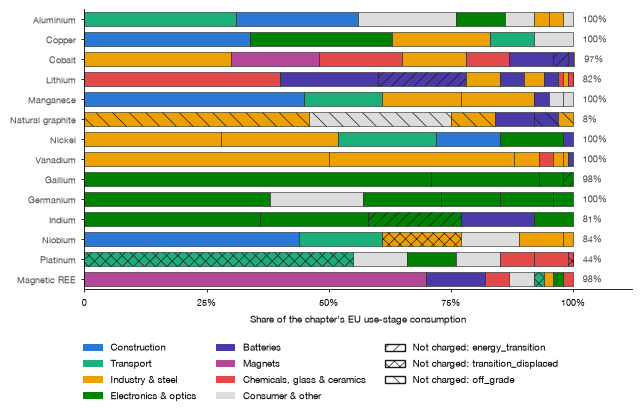

In [4]:
hatch_of = {
    EndUseClass.other: "",
    EndUseClass.energy_transition: ned_style["energy_transition_hatch"],
    EndUseClass.transition_displaced: ned_style["transition_displaced_hatch"],
    EndUseClass.off_grade: ned_style["off_grade_hatch"],
}
sector_color = ned_style["sector_color"]
sector_name = ned_style["sector_nice_name"]
by_material, by_element = ned_helpers.charged_fraction(end_use, composition)

materials = list(consumption.index)
panel = ned_style["panel"]
fig, ax = plt.subplots(figsize=(panel["width"], panel["height"]), layout="constrained")
for row, material in enumerate(materials):
    left = 0.0
    slices = end_use[end_use[MsaEndUse.material] == material].sort_values(
        str(MsaEndUse.share), ascending=False
    )
    for _, piece in slices.iterrows():
        ax.barh(
            row,
            piece[MsaEndUse.share],
            left=left,
            color=sector_color[piece[MsaEndUse.sector]],
            hatch=hatch_of[piece[MsaEndUse.end_use_class]],
            edgecolor=ink["primary"],
            linewidth=0.4,
            height=0.72,
        )
        left += piece[MsaEndUse.share]
    ax.text(
        left + 0.02,
        row,
        f"{by_material[material]:.0%}",
        va="center",
        fontsize=plt.rcParams["xtick.labelsize"],
        color=ink["secondary"],
    )

ax.set_yticks(range(len(materials)), materials, color=ink["secondary"])
ax.set_ylim(len(materials) - 0.5, -0.5)
ax.set_xlim(0, 1.12)
ax.set_xticks(np.arange(0, 1.01, 0.25), ["0", "25%", "50%", "75%", "100%"])
ax.set_xlabel("Share of the chapter's EU use-stage consumption")
ax.spines[["top", "right"]].set_visible(False)

legend = fig.legend(
    handles=[
        *plotting.patch_handles(list(sector_color), sector_color, sector_name),
        *[
            mpatches.Patch(
                facecolor="white", edgecolor=ink["primary"], hatch=hatch_of[cls],
                label=f"Not charged: {cls}",
            )
            for cls in (
                EndUseClass.energy_transition,
                EndUseClass.transition_displaced,
                EndUseClass.off_grade,
            )
        ],
    ],
    # Under the panel: a key in the right margin would set the figure wider
    # than the page.
    loc="outside lower center",
    ncol=3,
    frameon=False,
)
plotting.save_figure(fig, figures_dir, "ned_end_use_split", style, (legend,))

### 1c. Splitting the one multi-element chapter

MSA's `Magnetic REE` is **six** elements accounted together as `t mREE` — Nd, Pr,
Tb, Dy, Sm and Gd (MSA_2023 p.113) — of which this study tracks four. A level
cannot be charged to an element until the basket is divided, so
`data/msa_element_composition.csv` splits every slice of that pie between the
elements the chapter names for it (p.114, Table 33 p.116–117). Samarium and
gadolinium are carried through the split and then charged to nobody.

Only the *membership* of each slice is the chapter's; it prints no proportions
anywhere, so the shares themselves are this study's — equal parts to the elements
named, except that Nd and Pr divide theirs 3:1 (didymium), and except `Magnets`,
which takes an assumed NdFeB composition. `Magnets` is 70% of the pie, so that
assumption sets most of the split, and it is why `msa_aggregate` is rated
`medium` where `msa` is `high`. No plausible split, including charging the whole
basket to neodymium, moves any of the four metals off its cluster.

The bar is the whole 879 t of EU use-stage consumption; the shaded part of each
element's share is what survives the end-use verdicts.

of the Magnetic REE pie: 89.6% is charged to the four tracked elements, 8.4% falls to untracked Sm and Gd, and 2.0% is transition-displaced; nobody is charged the last two


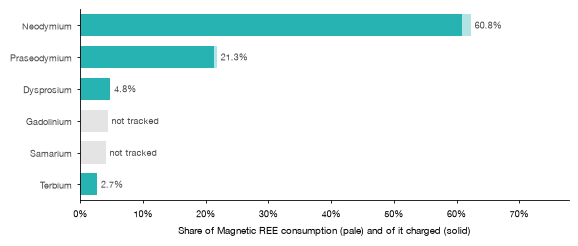

In [5]:
aggregate = composition[MsaComposition.material].unique()
assert len(aggregate) == 1, aggregate
material = aggregate[0]

pie = end_use[end_use[MsaEndUse.material] == material].set_index(str(MsaEndUse.application))
rows = composition[composition[MsaComposition.material] == material]
whole = (
    rows.assign(mass=rows[MsaComposition.mass_share] * pie[MsaEndUse.share]
                .reindex(rows[MsaComposition.application]).to_numpy())
    .groupby(MsaComposition.element)["mass"].sum()
    .sort_values(ascending=False)
)
charged = by_element.loc[material].reindex(whole.index).fillna(0.0)
tracked = set(mineral_info.index)

panel = ned_style["panel"]
fig, ax = plt.subplots(figsize=(panel["width"], panel["height"] * 0.62))
positions = np.arange(len(whole))
for position, element in zip(positions, whole.index):
    color = (
        group_color[mineral_info.loc[element, MineralInfo.group]]
        if element in tracked
        else ink["grid"]
    )
    ax.barh(position, whole[element], color=color, alpha=0.35, height=0.7)
    ax.barh(position, charged[element], color=color, height=0.7)
    note = f"{charged[element]:.1%}" if element in tracked else "not tracked"
    ax.text(
        whole[element] + 0.006, position, note, va="center",
        fontsize=plt.rcParams["xtick.labelsize"], color=ink["secondary"],
    )

ax.set_yticks(positions, whole.index, color=ink["secondary"])
ax.set_ylim(len(whole) - 0.5, -0.5)
ax.set_xlim(0, whole.max() * 1.25)
ax.set_xticks(np.arange(0, whole.max() * 1.2, 0.1),
              [f"{v:.0%}" for v in np.arange(0, whole.max() * 1.2, 0.1)])
ax.set_xlabel(f"Share of {material} consumption (pale) and of it charged (solid)")
ax.spines[["top", "right"]].set_visible(False)
plotting.save_figure(fig, figures_dir, "ned_magnet_ree_split", style)

kept = charged.reindex(sorted(tracked & set(whole.index))).sum()
print(
    f"of the {material} pie: {kept:.1%} is charged to the four tracked elements, "
    f"{charged.sum() - kept:.1%} falls to untracked Sm and Gd, and "
    f"{1 - charged.sum():.1%} is transition-displaced; nobody is charged the last two"
)

### 1d. The GDP path every level is carried on

Real GDP of the modelled country set, relative to the year the two series meet.
Observed history is OWID summed over the 34 countries; the projection is the
EU-27 potential-growth path of the 2024 Ageing Report (Table II.1.14).

Only a growth *rate* is taken from the Ageing Report — the level it is applied
to is the region's own — so the countries it does not cover (16% of regional
GDP, mostly the UK) cost under a percent across the window. The markers are the
anchor years: a metal's level is divided by the index at its own anchor, so the
2020 dip cancels for a chapter whose consumption was also measured in 2020.

2025-2050: 1.370x, i.e. 1.27%/yr


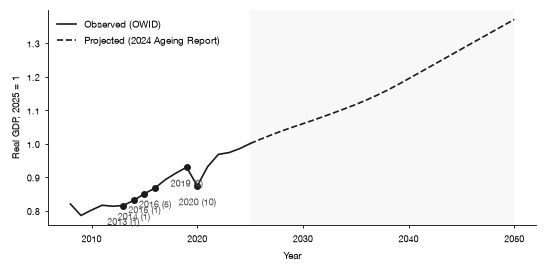

In [6]:
observed = gdp_index[gdp_index[GdpIndex.observed]]
projected = gdp_index[~gdp_index[GdpIndex.observed]]
splice_year = int(observed.index.max())

panel = ned_style["panel"]
fig, ax = plt.subplots(figsize=(panel["width"], panel["height"] * 0.7))
ax.plot(observed.index, observed[GdpIndex.gdp_index], color=ink["primary"], label="Observed (OWID)")
ax.plot(
    [splice_year, *projected.index],
    [observed[GdpIndex.gdp_index].iloc[-1], *projected[GdpIndex.gdp_index]],
    color=ink["primary"], linestyle="--", label="Projected (2024 Ageing Report)",
)
ax.axvspan(
    window["start_year"], window["end_year"],
    color=ink["grid"], alpha=0.25, linewidth=0, zorder=0,
)
for anchor, block in levels.groupby(levels[NedLevel.anchor_year].astype(int)):
    ax.plot(anchor, gdp_index.loc[anchor, GdpIndex.gdp_index], "o", color=ink["primary"], markersize=4)
    ax.annotate(
        f"{anchor} ({len(block)})",
        (anchor, gdp_index.loc[anchor, GdpIndex.gdp_index]),
        textcoords="offset points", xytext=(0, -14), ha="center",
        fontsize=plt.rcParams["xtick.labelsize"], color=ink["secondary"],
    )

ax.set_ylabel(f"Real GDP, {splice_year} = 1")
ax.set_xlabel("Year")
ax.spines[["top", "right"]].set_visible(False)
legend = ax.legend(frameon=False, loc="upper left")
plotting.save_figure(fig, figures_dir, "ned_gdp_index", style, (legend,))

span = gdp_index.loc[window["end_year"], GdpIndex.gdp_index] / gdp_index.loc[splice_year, GdpIndex.gdp_index]
years = window["end_year"] - splice_year
print(f"{splice_year}-{window['end_year']}: {span:.3f}x, i.e. {(span ** (1 / years) - 1):.2%}/yr")

## 2. Intermediate — the level each metal is anchored on

`build_ned_levels` writes one row per metal. Two readings:

- **`msa` / `msa_aggregate`** — the chapter's EU use-stage consumption, times
  `charged_fraction`, times `region_scale` (the modelled country set over the
  EU-27 or EU-28 the chapter describes).
- **`gdp`** — no chapter covers the metal, so a world other-sector series read at
  its last reported year, times the metal-blind GDP allocation share.

The level is where all the metal-specific information sits — the index above it
is common to every metal — so it is the number to check a result against. The
axis is logarithmic because the levels span six orders of magnitude, from
aluminium at 5,805 kt/yr to iridium at 1.4 t/yr.

In [7]:
levels.assign(
    **{
        "level (kt/yr)": levels[NedLevel.level_kt],
        "charged": levels[NedLevel.charged_fraction],
    }
)[
    [
        NedLevel.basis,
        NedLevel.anchor_year,
        NedLevel.msa_material,
        NedLevel.reference_consumption,
        NedLevel.unit,
        "charged",
        NedLevel.region_scale,
        NedLevel.world_anchor_source,
        "level (kt/yr)",
        NedLevel.confidence,
    ]
].round(4)

,basis,anchor_year,msa_material,reference_consumption,unit,charged,region_scale,world_anchor_source,level (kt/yr),confidence
metal,,,,,,,,,,
Aluminium,msa,2013,Aluminium,5464.00,kt,1.0000,1.0625,NaN,5805.3230,high
Cadmium,gdp,2019,NaN,NaN,NaN,NaN,NaN,schlichenmaier,8.1073,low
Cobalt,msa,2016,Cobalt,33.00,kt,0.9701,1.2251,NaN,39.2184,high
Copper,msa,2014,Copper,3000.00,kt,1.0000,1.0625,NaN,3187.4028,high
Dysprosium,msa_aggregate,2020,Magnetic REE,879.00,t,0.0480,1.2251,NaN,0.0517,medium
Gallium,msa,2020,Gallium,83.70,t,0.9800,1.2251,NaN,0.1005,high
Germanium,msa,2020,Germanium,44.25,t,1.0000,1.2251,NaN,0.0542,high
Graphite,msa,2016,Natural graphite,53.00,kt,0.0800,1.2251,NaN,5.1943,high
Indium,msa,2020,Indium,56.00,t,0.8100,1.2251,NaN,0.0556,high


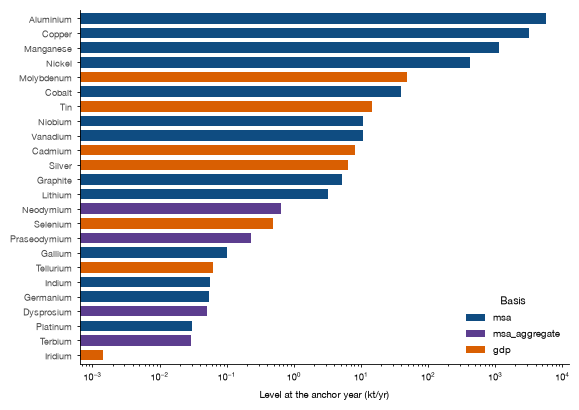

In [8]:
ordered = sorted(metals, key=lambda m: levels.loc[m, NedLevel.level_kt])
panel = ned_style["panel"]
fig, ax = plt.subplots(figsize=(panel["width"], panel["height"] * 1.15))
positions = np.arange(len(ordered))
ax.barh(
    positions,
    [levels.loc[m, NedLevel.level_kt] for m in ordered],
    color=[basis_color[levels.loc[m, NedLevel.basis]] for m in ordered],
    height=0.72,
)
ax.set_xscale("log")
ax.set_yticks(positions, ordered, color=ink["secondary"])
ax.set_ylim(-0.6, len(ordered) - 0.4)
ax.set_xlabel(f"Level at the anchor year ({ned_helpers.UNIT}/yr)")
ax.spines[["top", "right"]].set_visible(False)

legend = ax.legend(
    handles=plotting.patch_handles(
        list(basis_color), basis_color, {b: str(b) for b in basis_color}
    ),
    title="Basis",
    frameon=False,
    loc="lower right",
)
plotting.save_figure(fig, figures_dir, "ned_levels", style, (legend,))

## 3. Result — the projection and the window total

`build_non_energy_demand` multiplies each level by the GDP index relative to its
own anchor year. Every metal therefore grows at the same rate and differs only
in its level and in where that level was measured; the shaded span is the
window the totals are summed over.

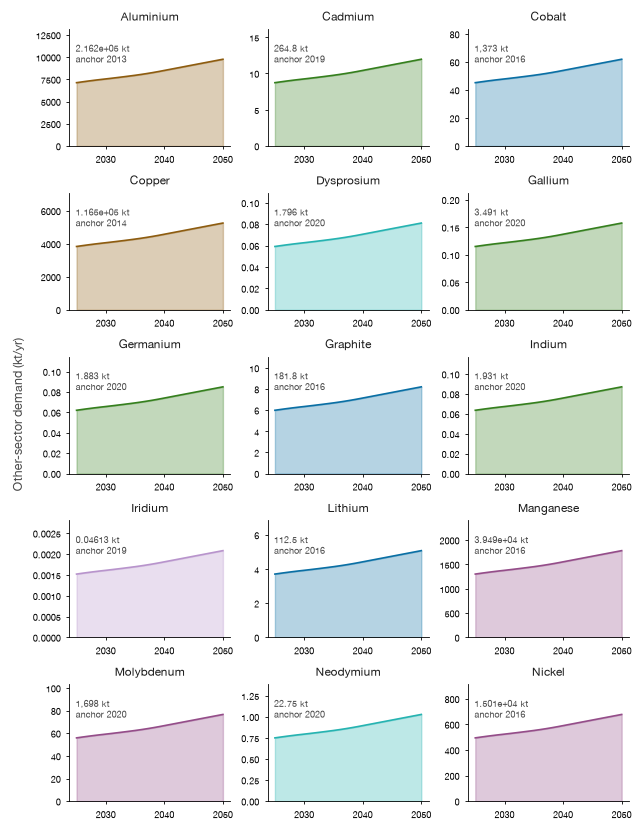

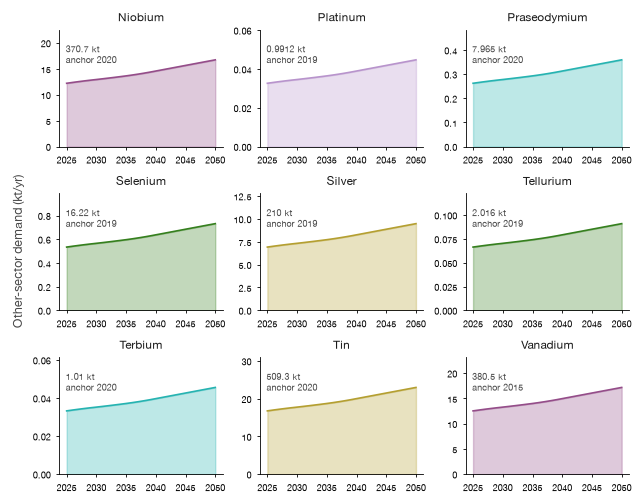

In [9]:
# Two dozen panels do not fit a page at the shared point sizes, so the grid is
# cut into pages rather than shrunk onto one.
for page, (fig, axes, page_metals) in enumerate(
    plotting.paged_grid(metals, style), start=1
):
    for ax, metal in zip(axes, page_metals):
        series = cube[ned_helpers.DEMAND].sel({ned_helpers.METAL_DIM: metal}).to_pandas()
        color = group_color[mineral_info.loc[metal, MineralInfo.group]]
        ax.fill_between(series.index, series.to_numpy(), color=color, alpha=0.3)
        ax.plot(series.index, series.to_numpy(), color=color)
        ax.set_ylim(0, series.max() * 1.35)
        ax.set_title(metal, color=ink["primary"])
        ax.text(
            0.04, 0.88,
            f"{float(cube[ned_helpers.TOTAL_DEMAND].sel({ned_helpers.METAL_DIM: metal})):,.4g} kt"
            f"\nanchor {int(levels.loc[metal, NedLevel.anchor_year])}",
            transform=ax.transAxes, va="top",
            fontsize=plt.rcParams["xtick.labelsize"], color=ink["secondary"],
        )
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=plt.rcParams["xtick.labelsize"])
    ylabel = fig.supylabel(
        f"Other-sector demand ({ned_helpers.UNIT}/yr)", color=ink["secondary"]
    )
    plotting.save_figure(fig, figures_dir, f"ned_series_{page}", style, (ylabel,))


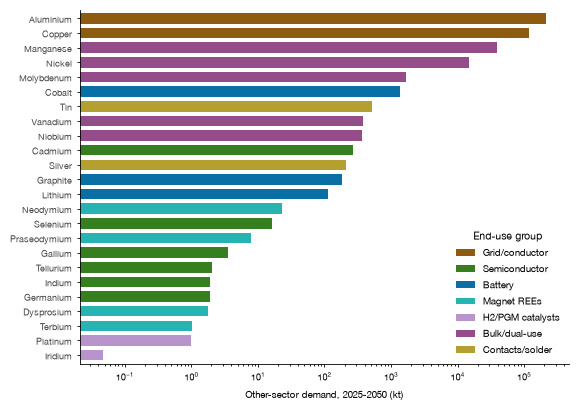

In [10]:
totals = cube[ned_helpers.TOTAL_DEMAND].to_pandas()
ordered = sorted(metals, key=lambda m: totals[m])
panel = ned_style["panel"]
fig, ax = plt.subplots(figsize=(panel["width"], panel["height"] * 1.15))
positions = np.arange(len(ordered))
ax.barh(
    positions,
    totals.reindex(ordered).to_numpy(),
    color=[group_color[mineral_info.loc[m, MineralInfo.group]] for m in ordered],
    height=0.72,
)
ax.set_xscale("log")
ax.set_yticks(positions, ordered, color=ink["secondary"])
ax.set_ylim(-0.6, len(ordered) - 0.4)
ax.set_xlabel(
    f"Other-sector demand, {window['start_year']}-{window['end_year']} "
    f"({ned_helpers.UNIT})"
)
ax.spines[["top", "right"]].set_visible(False)
legend = ax.legend(
    handles=plotting.patch_handles(
        list(groups), group_color, group_nice
    ),
    title="End-use group",
    frameon=False,
    loc="lower right",
)
plotting.save_figure(fig, figures_dir, "ned_totals", style, (legend,))

In [11]:
final.assign(
    **{
        "level (kt/yr)": final[NonEnergyDemand.level_kt],
        f"total {window['start_year']}-{window['end_year']} (kt)": final[
            NonEnergyDemand.total_demand_kt
        ],
        "growth over the window": (
            cube[ned_helpers.DEMAND].sel(year=window["end_year"])
            / cube[ned_helpers.DEMAND].sel(year=window["start_year"])
        ).to_pandas(),
    }
)[
    [
        NonEnergyDemand.basis,
        NonEnergyDemand.anchor_year,
        "level (kt/yr)",
        f"total {window['start_year']}-{window['end_year']} (kt)",
        "growth over the window",
        NonEnergyDemand.confidence,
    ]
].sort_index().round(4)

,basis,anchor_year,level (kt/yr),total 2025-2050 (kt),growth over the window,confidence
metal,,,,,,
Aluminium,msa,2013,5805.3230,216192.8780,1.3702,high
Cadmium,gdp,2019,8.1073,264.7853,1.3702,low
Cobalt,msa,2016,39.2184,1372.6434,1.3702,high
Copper,msa,2014,3187.4028,116477.4719,1.3702,high
Dysprosium,msa_aggregate,2020,0.0517,1.7957,1.3702,medium
Gallium,msa,2020,0.1005,3.4910,1.3702,high
Germanium,msa,2020,0.0542,1.8833,1.3702,high
Graphite,msa,2016,5.1943,181.8016,1.3702,high
Indium,msa,2020,0.0556,1.9305,1.3702,high


## 4. Checks

Three things that would each break the method quietly.

In [12]:
# (a) every metal grows by the same factor, since one index carries them all.
growth = (
    cube[ned_helpers.DEMAND].sel(year=window["end_year"])
    / cube[ned_helpers.DEMAND].sel(year=window["start_year"])
).to_pandas()
assert np.allclose(growth, growth.iloc[0]), growth
print(f"(a) every metal grows {growth.iloc[0]:.4f}x across the window")

# (b) the total is the level times the index summed over the window, which is
# the one line of arithmetic the cube is; recomputed here from the two inputs.
years = np.arange(window["start_year"], window["end_year"] + 1)
expected = pd.Series(
    {
        metal: levels.loc[metal, NedLevel.level_kt]
        / gdp_index.loc[int(levels.loc[metal, NedLevel.anchor_year]), GdpIndex.gdp_index]
        * gdp_index.loc[years, GdpIndex.gdp_index].sum()
        for metal in metals
    }
)
assert np.allclose(expected, cube[ned_helpers.TOTAL_DEMAND].to_pandas()[expected.index])
print("(b) totals reproduce from ned_levels.csv x gdp_index.csv")

# (c) what the per-metal measurement is worth against the metal-blind share it
# replaces, for the metals whose world series is on hand.
world = levels[levels[NedLevel.world_demand_kt].notna()]
print(
    f"(c) the metal-blind GDP share is {blind_share:.1%} of world demand and is "
    f"applied to {len(world)} metals; the other {len(levels) - len(world)} carry "
    "a level measured from their own chapter"
)

(a) every metal grows 1.3702x across the window
(b) totals reproduce from ned_levels.csv x gdp_index.csv
(c) the metal-blind GDP share is 17.9% of world demand and is applied to 7 metals; the other 17 carry a level measured from their own chapter


## Assumptions this rests on

Set out in full in the `scripts/non_energy_helpers.py` docstring, and all four
visible above:

- **The end-use verdicts are conservative.** Where MSA lumps a modelled
  technology in with much else — aluminium's "Electrical engineering", the magnet
  REEs' "Magnets" — the slice stays `other`, so a level is an upper bound.
- **A `transition_displaced` slice goes to zero in one step**, from the first
  window year rather than on a trajectory, which biases platinum, niobium and the
  magnet REEs low by at most the slice itself.
- **Other-sector demand grows with GDP and nothing else** — no intensity-of-use
  decline, no saturation, no substitution. Unit elasticity is this study's own
  assumption rather than one inherited undisclosed from a world projection.
- **The magnet REE element split** (§1c) is a study verdict built on the
  chapter's element attribution, not a measurement; `msa_aggregate` is rated down
  for it.